<center><h1>Batra_Raghav_Q8</h1></center>
<br>
<br>

Name: Raghav Batra
<br>
Github Username: rbatra02
<br>
USC ID: 3227519293

In [25]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

Data Exploration and Preprocessing

i, ii

In [26]:
DATA_DIR = "../student"

df = pd.read_csv("../student/student-mat.csv", sep=";")

cols = ["age", "studytime", "schoolsup", "goout", "Dalc", "Walc", "health", "absences", "G3"]

data =df[cols].copy()

data["schoolsup"] = data["schoolsup"].map({"no": 0, "yes": 1})
data["alc"] = (data["Walc"] + data["Dalc"]) / 2 
data = data.drop(columns=["Dalc", "Walc"])

data.head()



,age,studytime,schoolsup,goout,health,absences,G3,alc
0,18,2,1,4,3,6,6,1.0
1,17,2,0,3,3,4,6,1.0
2,15,2,1,2,3,10,10,2.5
3,15,3,0,2,5,2,15,1.0
4,16,2,0,2,5,4,10,1.5


### (iii) Outliers 

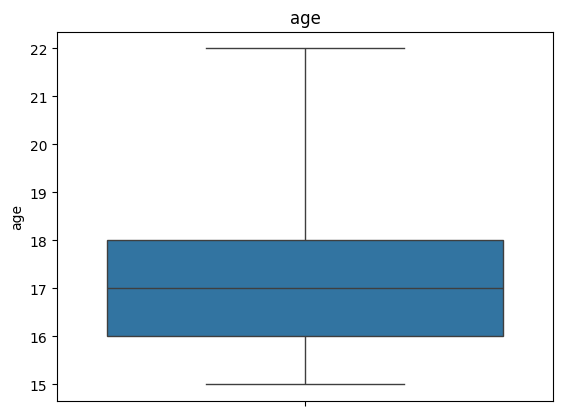

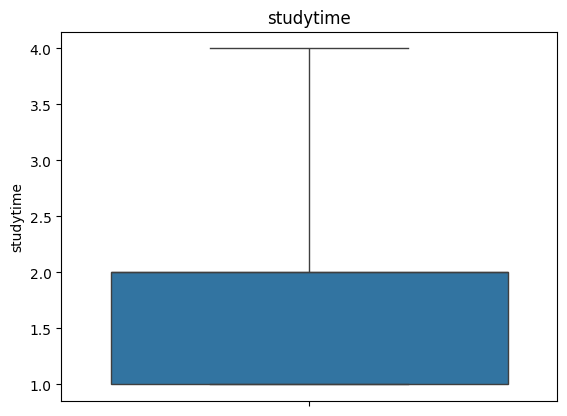

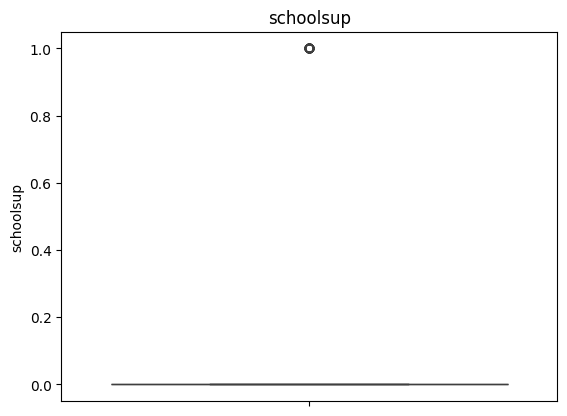

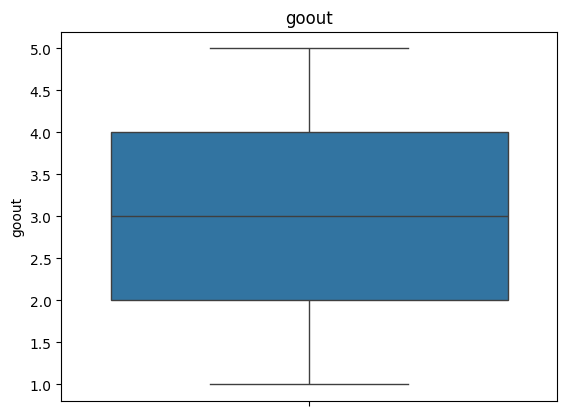

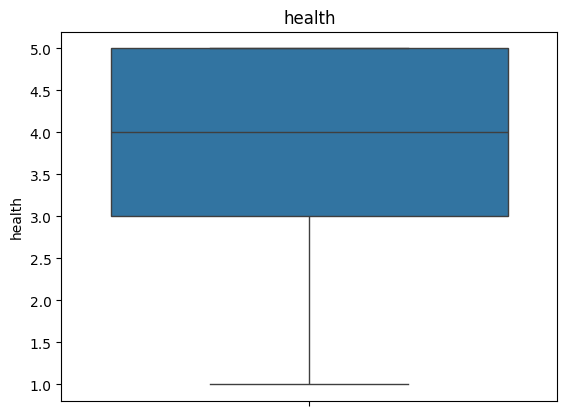

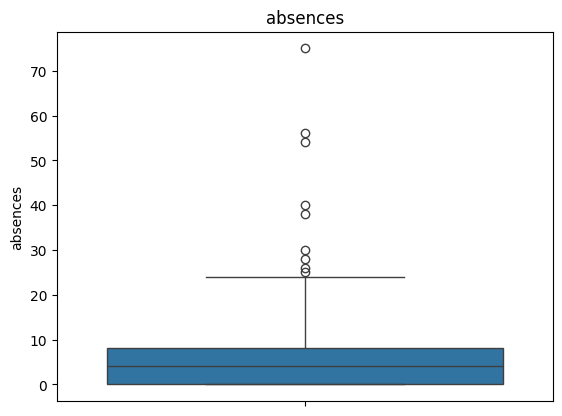

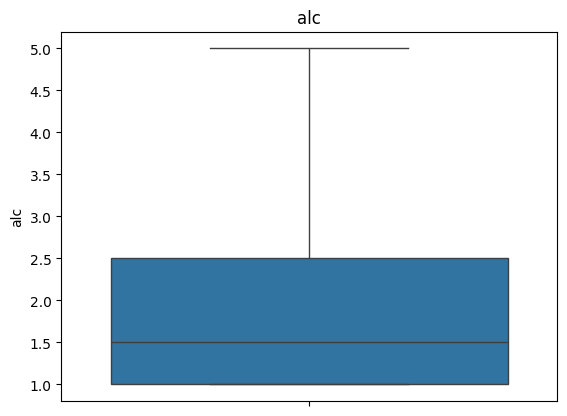

Total outliers: 
age           1
studytime    27
schoolsup    51
goout         0
health        0
absences     15
alc           9
dtype: int64


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns


X = data.drop(columns="G3")
y = data["G3"]


Q1, Q3 = X.quantile(0.25), X.quantile(0.75)
IQR = Q3 - Q1

col_names = []

outliers = ((X < Q1 - 1.5*IQR) | (X > Q3 + 1.5*IQR)).sum()

for col in X.columns:
    ax = sns.boxplot(data=X, y=col, whis=2.0)
    plt.title(col)
    plt.show()

print(f"Total outliers: \n{outliers}")

### (iv) PCA

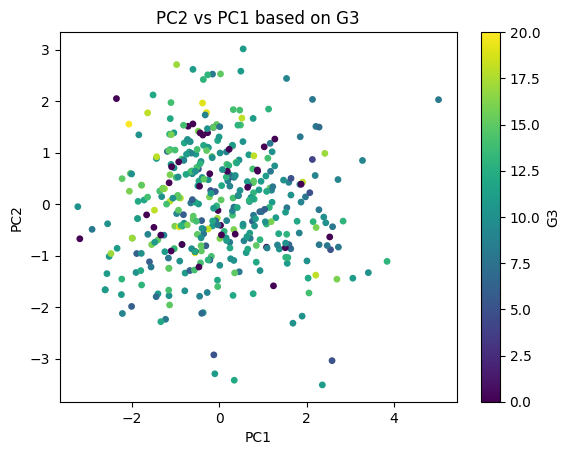

             PC1    PC2
age        0.382  0.589
studytime -0.330  0.386
schoolsup -0.248 -0.464
goout      0.494 -0.140
health     0.081 -0.401
absences   0.280  0.183
alc        0.596 -0.274


In [28]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

X_std = pd.DataFrame(StandardScaler().fit_transform(X), columns=X.columns)

pca = PCA()
pcs = pca.fit_transform(X_std)

plt.scatter(pcs[:, 0], pcs[:,1], c=y, cmap="viridis", s=15)
plt.colorbar(label="G3")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("PC2 vs PC1 based on G3")
plt.show()

loadings = pd.DataFrame(pca.components_[:2].T, index=X.columns, columns=["PC1", "PC2"])
print(loadings.round(3))






PC1 alc contributes the most and PC2 age contributes the most. 

#### b. Linear Regression

i)

In [29]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X_std, y, test_size=0.2, random_state=552)

ii, iii)

In [30]:
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score

models={
    "Linear": LinearRegression(),
    "Ridge": Ridge(alpha=0.1),
    "Lasso": Lasso(alpha=0.1),

}

results = {}
for name, m in models.items(): 
    m.fit(X_train, y_train)
    pred = m.predict(X_test)
    results[name] = {
        "Mean Abs Error": mean_absolute_error(y_test, pred),
        "Root Mean Squared Error": root_mean_squared_error(y_test, pred),
        "R2": r2_score(y_test,pred)
    }
result = pd.DataFrame(results).T.round(6)

print(result)
print("Best Mean Abs Error: ", result["Mean Abs Error"].idxmin())
print("Best Root Mean Squared Error: ", result["Root Mean Squared Error"].idxmin())
print("Best R2: ", result["R2"].idxmax())


        Mean Abs Error  Root Mean Squared Error        R2
Linear        3.418009                 4.755812  0.028177
Ridge         3.418062                 4.755859  0.028157
Lasso         3.447073                 4.793840  0.012573
Best Mean Abs Error:  Linear
Best Root Mean Squared Error:  Linear
Best R2:  Linear


iv) 
R^2 represents the fraction of the total variation in G3 explained by each model.

2.817% of the total variation in G3 is explained by the Linear Regression Model.

2.815% of the total variation in G3 is explained by the Ridge Regularization Model.

1.257% of the total variation in G3 is explained by the Lasso Regularization Model.

v)

In [31]:
coefs = pd.DataFrame({name: m.coef_ for name, m in models.items()}, index=X.columns)
intercepts = pd.DataFrame({name: m.intercept_ for name, m in models.items()}, index=['intercept'])

all_params = pd.concat([coefs, intercepts]).round(4)

print(all_params)


            Linear    Ridge    Lasso
age        -0.7811  -0.7807  -0.6304
studytime   0.4448   0.4447   0.3491
schoolsup  -0.6825  -0.6822  -0.5475
goout      -0.5825  -0.5823  -0.4856
health     -0.2433  -0.2432  -0.1416
absences    0.1928   0.1927   0.0720
alc         0.0371   0.0369  -0.0000
intercept  10.6294  10.6294  10.6251


vi)

Using the Linear coefficients:

Age: For one standard deviation increase in age results in decrease of 0.78 change on average in G3 holding all other variables constant.

Studytime: For one standard deviation increase in studytime  results in increase of 0.44 on average change in G3 holding all other variables constant.

SchoolSup: For one standard deviation increase in schoolsup results in decrease of 0.68 on average in G3 holding all other variables constant. 

Goout: for one standard deviation increase in goout results in decrease of 0.58 on average in G3 holding all other variables constant.

health: for one standard deviation increase in health results in decrease of 0.24 on average in G3 holding all other variables constant.

absences: for one standard deviation increase in absences results in increase of 0.19 on average in G3 holding all other variables constant.

alc: for one standard deviation increase in alc results in increase of 0.037 on average in G3 holding all other variables constant. 

vii)

For Ridge the coefficients shrink towards 0, but do not actually become 0 like alc at 0.0369.

For Lasso the coefficients shrink towards 0 and eventually do become 0 like alc. 

From the small R^2 values it seems that the features don't explain G3 very well. 

viii)
as alpha increases the betas approach 0 which will increase the test MAE and RMSE. 

xi) Some examples include one hot encoding, ploynomial and interaction features, and log transforms.